In [1]:
import os

DATASET_PATH = "/kaggle/input/datasets/maram05ai/clevr-cogent-v1"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nDataset contents:")

for item in sorted(os.listdir(DATASET_PATH)):
    path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(path):
        print(f"\n📁 {item}/")
        print("   ", sorted(os.listdir(path)))

    else:
        print(f"📄 {item}")

Dataset exists: True

Dataset contents:

📁 CLEVR_CoGenT_v1.0/
    ['COPYRIGHT.txt', 'LICENSE.txt', 'README.txt', 'images', 'questions', 'scenes']


In [2]:
import os

DATASET_PATH = "/kaggle/input/datasets/maram05ai/clevr-cogent-v1/CLEVR_CoGenT_v1.0"

for folder in ["images", "scenes", "questions"]:
    path = os.path.join(DATASET_PATH, folder)

    print(f"\n{'='*50}")
    print(f"FOLDER: {folder}")
    print(f"Exists: {os.path.exists(path)}")

    if os.path.exists(path):
        items = os.listdir(path)
        print(f"Number of items: {len(items)}")

        for item in sorted(items)[:15]:
            item_path = os.path.join(path, item)
            if os.path.isdir(item_path):
                print(f"  📁 {item}/")
            else:
                print(f"  📄 {item}")


FOLDER: images
Exists: True
Number of items: 5
  📁 testA/
  📁 testB/
  📁 trainA/
  📁 valA/
  📁 valB/

FOLDER: scenes
Exists: True
Number of items: 3
  📄 CLEVR_trainA_scenes.json
  📄 CLEVR_valA_scenes.json
  📄 CLEVR_valB_scenes.json

FOLDER: questions
Exists: True
Number of items: 5
  📄 CLEVR_testA_questions.json
  📄 CLEVR_testB_questions.json
  📄 CLEVR_trainA_questions.json
  📄 CLEVR_valA_questions.json
  📄 CLEVR_valB_questions.json


In [3]:
import json
import os

SCENES_PATH = os.path.join(DATASET_PATH, "scenes")

scene_file = os.path.join(
    SCENES_PATH,
    "CLEVR_trainA_scenes.json"
)

with open(scene_file, "r") as f:
    scenes_data = json.load(f)

print("Top-level keys:")
print(scenes_data.keys())

print("\nNumber of scenes:")
print(len(scenes_data["scenes"]))

print("\nFirst scene structure:")
first_scene = scenes_data["scenes"][0]

print("Scene keys:")
print(first_scene.keys())

print("\nImage filename:")
print(first_scene.get("image_filename"))

print("\nNumber of objects:")
print(len(first_scene["objects"]))

print("\nFirst object:")
print(json.dumps(first_scene["objects"][0], indent=4))

Top-level keys:
dict_keys(['scenes', 'info'])

Number of scenes:
70000

First scene structure:
Scene keys:
dict_keys(['image_filename', 'objects', 'split', 'image_index', 'relationships', 'directions'])

Image filename:
CLEVR_trainA_000000.png

Number of objects:
3

First object:
{
    "pixel_coords": [
        131,
        173,
        9.2485990524292
    ],
    "size": "large",
    "color": "yellow",
    "material": "metal",
    "shape": "sphere",
    "3d_coords": [
        0.044448722153902054,
        -2.6995933055877686,
        0.699999988079071
    ],
    "rotation": 303.2391460924107
}


Image filename: CLEVR_trainA_000000.png
Image dimensions: (480, 320)
Number of objects: 3

Objects information:

Object 1
Shape: sphere
Color: yellow
Material: metal
Size: large
Pixel coordinates: [131, 173, 9.2485990524292]

Object 2
Shape: cylinder
Color: cyan
Material: metal
Size: large
Pixel coordinates: [252, 114, 11.72614574432373]

Object 3
Shape: sphere
Color: gray
Material: rubber
Size: small
Pixel coordinates: [196, 115, 12.643919944763184]


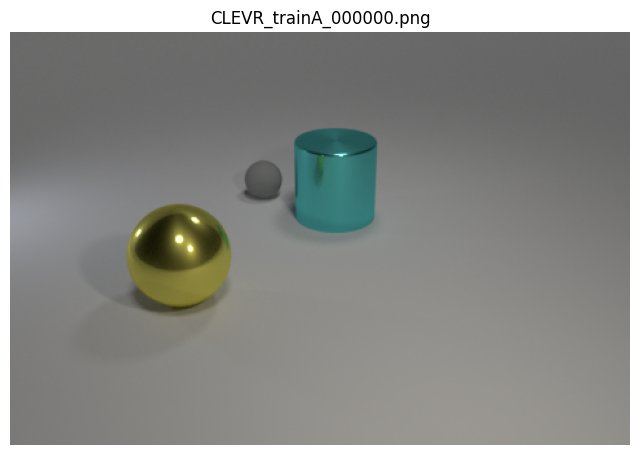

In [4]:
import os
import json
from PIL import Image
import matplotlib.pyplot as plt

# Load the first scene
scene = scenes_data["scenes"][0]

# Load its corresponding image
image_path = os.path.join(
    DATASET_PATH,
    "images",
    "trainA",
    scene["image_filename"]
)

image = Image.open(image_path)

print("Image filename:", scene["image_filename"])
print("Image dimensions:", image.size)
print("Number of objects:", len(scene["objects"]))

print("\nObjects information:")

for i, obj in enumerate(scene["objects"]):
    print(f"\nObject {i + 1}")
    print("Shape:", obj["shape"])
    print("Color:", obj["color"])
    print("Material:", obj["material"])
    print("Size:", obj["size"])
    print("Pixel coordinates:", obj["pixel_coords"])

# Display image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.title(scene["image_filename"])
plt.show()

In [2]:
import os

print("Available Kaggle inputs:\n")

for item in os.listdir("/kaggle/input"):
    print(item)

Available Kaggle inputs:

datasets


In [3]:
import os

root = "/kaggle/input"

for current_path, dirs, files in os.walk(root):
    level = current_path.replace(root, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(current_path)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

input/
    datasets/
        maram05ai/
            clevr-cogent-v1/


In [ ]:
zip_path = os.path.join(
    DATASET_PATH,
    "CLEVR_CoGenT_v1.0.zip"
)

with zipfile.ZipFile(zip_path, "r") as archive:
    files = archive.namelist()

    print("Total files:", len(files))
    print("\nFirst 40 files:")

    for file in files[:40]:
        print(file)

## Current Progress — November 7, 2026

### Completed
- Created GitHub repository.
- Created Kaggle dataset: CLEVR-CoGenT v1.0.
- Connected dataset to Kaggle notebook.
- Established Object-level Classification as the initial approach.

### Pending
- Inspect images, scenes, and questions directories.
- Investigate why the directory inspection returned no files.
- Examine Scene Graph annotations.
- Verify object coordinates and bounding-box extraction feasibility.

### Current Experiment
Experiment 001 — Dataset Structure & Annotation Inspection

Status: In Progress